# Backtracking y el recorrido del caballo

**Inteligencia Artificial · IS784 · Taller de laboratorio**

Un caballo debe visitar cada casilla del tablero exactamente una vez. Puede terminar en cualquier casilla en un **recorrido abierto**. Para un **recorrido cerrado**, además debe poder saltar de la última casilla a la inicial. En este taller, «abierto» significa que no se exige el salto de regreso.

**Objetivos**

- Representar una solución parcial y formular el caso base de una búsqueda recursiva.
- Explicar qué debe restaurarse al abandonar una rama.
- Implementar, probar y animar un solucionador propio.
- Medir el efecto del orden de exploración sobre el trabajo de la búsqueda.

Las coordenadas son pares `(fila, columna)` numerados desde cero. La fila crece hacia abajo. Un salto legal cumple `(|Δfila|, |Δcolumna|) = (1, 2)` o `(2, 1)`. Por ejemplo, desde `(0, 0)` se puede ir a `(1, 2)` o a `(2, 1)`.

Ejecute las celdas en orden con Python 3. La animación ya está incluida en el cuaderno. Para regenerarla se necesitan Pillow y Matplotlib. Si faltan en su entorno de Jupyter, ejecute `%pip install pillow matplotlib` en una celda y vuelva a ejecutar el cuaderno.

### Autor y organización de la solución

**Autor:** Santiago Guevara (taller individual).

- **Código propio:** está en la celda de los Retos 1–3, en la sección 3. Es el mismo código de `caballo/solver.py`, probado con `pytest` (`tests/test_solver.py`).
- **Celdas agregadas:** después de cada parte del enunciado están mis respuestas, las pruebas, la tabla comparativa, la animación de mi propia ejecución y la traza manual anotada.
- **Ejecución:** el cuaderno se ejecuta de arriba abajo con un kernel nuevo, sin datos externos.

**Declaración de ayudas.** El docente autorizó el uso de IA declarada. Usé un asistente de IA (Claude, mediante Claude Code) para:
- discutir el contrato;
- escribir y revisar el código y las pruebas;
- redactar las explicaciones.

Revisé, ejecuté y puedo explicar todo el código. Las trazas manuales y las predicciones de la sustentación las hago yo. Bibliotecas usadas: Matplotlib y Pillow, solo para la animación suministrada.

## 1. Elegir, explorar y deshacer

Cada nodo del árbol de búsqueda representa un **camino parcial**. Sus hijos corresponden a saltos legales que aún no aparecen en ese camino. Una misma posición puede aparecer en diferentes ramas porque las demás casillas visitadas pueden ser distintas.

Conserve dos estructuras: `camino`, que guarda el orden de los saltos, y `visitadas`, que permite comprobar la pertenencia con un conjunto. Justo antes y después de explorar una rama fallida debe mantenerse el invariante `visitadas == set(camino)`. Al volver de esa rama se debe haber recuperado exactamente el camino anterior, en el mismo orden.

```text
BUSCAR
    si el camino ocupa todas las casillas:
        devolver si cumple la condición del recorrido

    para cada destino legal y libre desde la última casilla:
        agregar el destino al camino y marcarlo como visitado
        si BUSCAR devuelve éxito:
            devolver éxito
        quitar el destino del camino y desmarcarlo

    devolver fracaso
```

Una llamada puede fracasar porque se quedó sin destinos libres o porque agotó todos sus descendientes. Cuando eso ocurre, su llamador deshace el salto que lo llevó allí y prueba la siguiente alternativa. Si una rama tiene éxito, las llamadas retornan conservando el camino completo.

Con `N` casillas, la pila recursiva puede alcanzar profundidad `N`. Un límite superior grueso para el árbol es `O(8^N)`; las restricciones reducen la cantidad de ramas efectivas. El camino, el conjunto y la pila usan `O(N)` de espacio. Guardar todos los eventos de animación añade espacio lineal en el número de eventos registrados.

## 2. Observe un retroceso

La traza se grabó en un tablero **5×5**, desde **(0, 0)**, con un orden fijo de movimientos escogido para que se vean varios retrocesos en poco tiempo. El verde señala un avance. En naranja, el caballo queda en la casilla a la que volvió y el aspa marca la casilla que acaba de liberar. Los números muestran la posición de cada casilla en el camino actual. La animación se repite automáticamente.

Antes de verla, prediga qué ocurre con el último número del tablero cuando el caballo retrocede. Después, use el visor de fotogramas para comprobar su predicción.

In [1]:
TRAZA_DEMO = [('inicio', 0, 0), ('avance', 1, 2), ('avance', 0, 4), ('avance', 2, 3), ('avance', 4, 4), ('avance', 3, 2), ('avance', 2, 4), ('avance', 4, 3), ('avance', 3, 1), ('avance', 1, 0), ('avance', 0, 2), ('avance', 1, 4), ('avance', 3, 3), ('avance', 4, 1), ('avance', 2, 0), ('avance', 0, 1), ('avance', 1, 3), ('avance', 3, 4), ('avance', 4, 2), ('avance', 3, 0), ('avance', 2, 2), ('avance', 0, 3), ('avance', 1, 1), ('retroceso', 1, 1), ('retroceso', 0, 3), ('retroceso', 2, 2), ('avance', 1, 1), ('avance', 0, 3), ('avance', 2, 2), ('retroceso', 2, 2), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 2, 2), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 1, 1), ('avance', 0, 3), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 0, 3), ('avance', 1, 1), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('éxito', 4, 0)]

In [2]:
from io import BytesIO

from IPython.display import Image as NotebookImage, display
from matplotlib import get_data_path
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

FONT_DIR = Path(get_data_path()) / "fonts" / "ttf"
FONT = FONT_DIR / "DejaVuSans.ttf"
TEXT_FONT = ImageFont.truetype(str(FONT), 17)
TITLE_FONT = ImageFont.truetype(str(FONT), 20)
HORSE_FONT = ImageFont.truetype(str(FONT), 31)

LABELS = {
    "inicio": "Inicio", "avance": "Avance", "retroceso": "Retroceso",
    "éxito": "Recorrido completo", "fracaso": "Búsqueda agotada",
    "límite": "Presupuesto agotado",
}


def dibujar_fotograma(n, camino, evento, indice):
    """Dibuja el camino después de aplicar el evento."""
    paso = min(60, 380 // n)
    margen_x, margen_y = 40, 66
    ancho = n * paso
    fondo = Image.new("RGB", (max(415, ancho + 66), ancho + 117), "#f8fafc")
    draw = ImageDraw.Draw(fondo)
    tipo, fila, columna = evento
    color = "#b45309" if tipo == "retroceso" else "#047857"
    draw.text((16, 11), f"{indice:02d} · {LABELS[tipo]}", font=TITLE_FONT,
              fill=color if tipo in {"avance", "retroceso", "éxito"} else "#0f172a")

    def esquina(f, c):
        return margen_x + c * paso, margen_y + f * paso

    for f in range(n):
        draw.text((19, margen_y + f * paso + paso / 2), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        draw.text((margen_x + f * paso + paso / 2, 52), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        for c in range(n):
            x, y = esquina(f, c)
            base = "#e2e8f0" if (f + c) % 2 == 0 else "#b8cadb"
            draw.rectangle((x, y, x + paso - 1, y + paso - 1), fill=base)

    for numero, (f, c) in enumerate(camino, start=1):
        x, y = esquina(f, c)
        actual = numero == len(camino)
        draw.rectangle((x + 2, y + 2, x + paso - 3, y + paso - 3),
                       fill=color if actual else "#d1fae5")
        if actual:
            draw.text((x + paso / 2, y + paso * 0.59), "♞", font=HORSE_FONT,
                      anchor="mm", fill="#ffffff")
            draw.text((x + 5, y + 2), str(numero), font=TEXT_FONT, fill="#ffffff")
        else:
            draw.text((x + paso / 2, y + paso / 2), str(numero), font=TEXT_FONT,
                      anchor="mm", fill="#064e3b")

    if tipo == "retroceso":
        x, y = esquina(fila, columna)
        draw.rectangle((x + 3, y + 3, x + paso - 4, y + paso - 4),
                       outline=color, width=3)
        draw.text((x + paso / 2, y + paso / 2), "×", font=HORSE_FONT,
                  anchor="mm", fill=color)

    draw.text((16, margen_y + ancho + 14),
              f"Visitadas {len(camino)}/{n*n} · Evento en ({fila}, {columna})",
              font=TEXT_FONT, fill="#0f172a")
    return fondo


def fotogramas(n, traza):
    """Reproduce eventos ya registrados; la búsqueda ocurre por separado."""
    camino = []
    for indice, evento in enumerate(traza):
        tipo, fila, columna = evento
        casilla = (fila, columna)
        if tipo in {"inicio", "avance"}:
            camino.append(casilla)
        elif tipo == "retroceso":
            if len(camino) < 2 or camino[-1] != casilla:
                raise ValueError(f"Retroceso incoherente en el evento {indice}")
            camino.pop()
        yield dibujar_fotograma(n, camino, evento, indice)


def gif_traza(n, traza):
    cuadros = list(fotogramas(n, traza))
    duraciones = [650 if evento[0] == "retroceso" else 280 for evento in traza]
    duraciones[0] = 950
    duraciones[-1] = 2200
    archivo = BytesIO()
    cuadros[0].save(archivo, format="GIF", save_all=True, append_images=cuadros[1:],
                    duration=duraciones, loop=0)
    return archivo.getvalue()

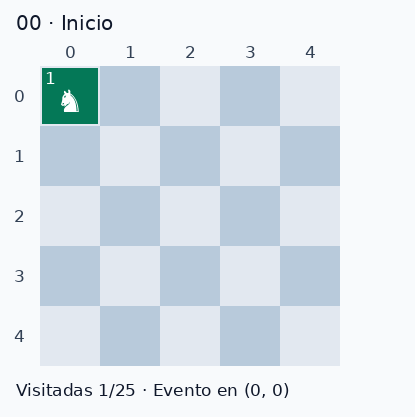

In [3]:
gif_demo = gif_traza(5, TRAZA_DEMO)
salida_gif = gif_demo, "image/gif"
display(NotebookImage(data=gif_demo, format="gif"))

### Laboratorio de observación

1. Seleccione el primer fotograma de retroceso. Registre las coordenadas de la casilla liberada y de la casilla a la que vuelve el caballo. ¿Cuántas casillas están visitadas antes y después?
2. Dibuje la pila de llamadas para los últimos tres niveles justo antes y después de ese retroceso. Localice el marco que elige el siguiente destino.
3. Encuentre en la traza una casilla que se libera y más tarde vuelve a aparecer como destino. Explique por qué esa segunda visita es válida.

### Mis respuestas al laboratorio de observación

**Predicción, antes de ver la animación.** Cuando el caballo retrocede, **desaparece el número más alto del tablero**: el camino pierde su último elemento y la casilla vuelve a estar libre. El caballo queda en la casilla que tenía el número anterior. La celda siguiente lo comprueba sobre `TRAZA_DEMO`.

1. **Primer retroceso: evento 23.**
   - Se libera **(1, 1)** y el caballo vuelve a **(0, 3)**.
   - Antes había **23** casillas visitadas; después hay **22**. El número 23 desaparece del tablero.
2. **Pila de llamadas.** Cada marco es una llamada a BUSCAR, identificada por la última casilla de su camino.
   - **Antes:** `… → (2, 2) → (0, 3) → (1, 1)`. El marco de (1, 1) recorrió sus destinos y no encontró ninguno libre, así que devuelve fracaso.
   - **Después:** `… → (3, 0) → (2, 2) → (0, 3)`. El marco de **(0, 3)** quita (1, 1) del camino y del conjunto, y es el que **elige el siguiente destino** de su lista. Como no le queda ninguno libre, también retrocede (evento 24).
3. **Casilla liberada que reaparece.** (1, 1) se libera en el evento 23 y vuelve a ser destino en el evento 26. Esa segunda visita es válida porque:
   - al retroceder se **desmarcó**, así que ya no pertenece al camino actual;
   - ahora el camino es distinto: se llega a (1, 1) desde (3, 0) y no desde (0, 3).

   Un nodo del árbol es un **camino parcial**, no una casilla. La misma casilla puede aparecer en ramas diferentes.

In [4]:
# ===== Laboratorio de observacion: respuestas calculadas sobre TRAZA_DEMO =====
def caminos_por_evento(traza):
    """Camino actual DESPUES de aplicar cada evento (reconstruido desde la traza)."""
    camino, estados = [], []
    for tipo, f, c in traza:
        if tipo in ("inicio", "avance"):
            camino.append((f, c))
        elif tipo == "retroceso":
            assert camino[-1] == (f, c)
            camino.pop()
        estados.append(list(camino))
    return estados


estados_demo = caminos_por_evento(TRAZA_DEMO)
i_ret = next(i for i, e in enumerate(TRAZA_DEMO) if e[0] == "retroceso")
antes, despues = estados_demo[i_ret - 1], estados_demo[i_ret]
print(f"1) Primer retroceso: evento {i_ret}. Casilla liberada {TRAZA_DEMO[i_ret][1:]}; "
      f"el caballo vuelve a {despues[-1]}.")
print(f"   Visitadas antes: {len(antes)}; despues: {len(despues)}. "
      f"El ultimo numero del tablero ({len(antes)}) desaparece.")
print("2) Pila (ultimos tres marcos; cada marco = una llamada BUSCAR con su ultima casilla):")
print("   antes  :", " -> ".join(map(str, antes[-3:])), "(el marco de", antes[-1], "no tiene destinos libres)")
print("   despues:", " -> ".join(map(str, despues[-3:])),
      "(el marco de", despues[-1], "elige su siguiente destino)")
for i, (tipo, f, c) in enumerate(TRAZA_DEMO):
    if tipo != "retroceso":
        continue
    j = next((k for k in range(i + 1, len(TRAZA_DEMO))
              if TRAZA_DEMO[k][0] == "avance" and TRAZA_DEMO[k][1:] == (f, c)), None)
    if j is not None:
        print(f"3) La casilla {(f, c)} se libera en el evento {i} y vuelve como destino en el evento {j}: "
              f"ahora se llega desde {estados_demo[j - 1][-1]} y no desde {estados_demo[i - 1][-2]}.")
        break


1) Primer retroceso: evento 23. Casilla liberada (1, 1); el caballo vuelve a (0, 3).
   Visitadas antes: 23; despues: 22. El ultimo numero del tablero (23) desaparece.
2) Pila (ultimos tres marcos; cada marco = una llamada BUSCAR con su ultima casilla):
   antes  : (2, 2) -> (0, 3) -> (1, 1) (el marco de (1, 1) no tiene destinos libres)
   despues: (3, 0) -> (2, 2) -> (0, 3) (el marco de (0, 3) elige su siguiente destino)
3) La casilla (1, 1) se libera en el evento 23 y vuelve como destino en el evento 26: ahora se llega desde (3, 0) y no desde (0, 3).


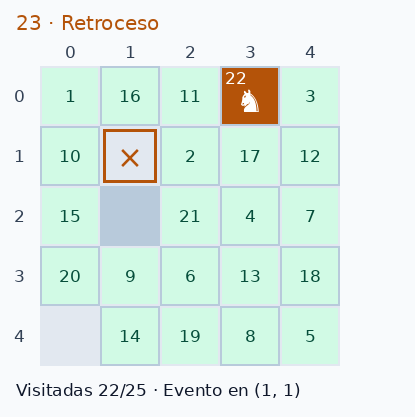

In [5]:
from itertools import islice


def ver_fotograma(n, traza, indice):
    if not 0 <= indice < len(traza):
        raise IndexError(f"Use un índice entre 0 y {len(traza) - 1}")
    cuadro = next(islice(fotogramas(n, traza), indice, None))
    archivo = BytesIO()
    cuadro.save(archivo, format="PNG")
    return archivo.getvalue()


indice = next(i for i, evento in enumerate(TRAZA_DEMO) if evento[0] == "retroceso")
# Cambie indice por indice - 1 o indice + 1 para comparar.
imagen_paso = ver_fotograma(5, TRAZA_DEMO, indice)
salida_paso = imagen_paso, "image/png"
display(NotebookImage(data=imagen_paso, format="png"))

## 3. Implemente su solucionador

### Reto 1 · Genere saltos legales

Complete `saltos_legales`. Use los ocho desplazamientos, compruebe los límites y descarte toda casilla de `visitadas`. Conserve el orden de entrada. Compruebe a mano los casos de una esquina, una casilla central y un tablero pequeño donde no cabe ningún salto.

### Reto 2 · Construya la búsqueda recursiva

Complete `resolver` para recorridos abiertos y pruebe primero con tableros de 1×1, 3×3 y 5×5. Use un conjunto para las visitadas y deje el registro de eventos bajo el control de las operaciones que modifican el camino. Elija una rama fallida de su propia ejecución y compruebe el invariante antes y después de explorarla.

**Contrato**

- `resolver` recibe `n` entero positivo, un inicio dentro del tablero, una permutación de `DESPLAZAMIENTOS`, y una estrategia `"fijo"` o `"warnsdorff"`. El presupuesto es un entero positivo.
- Devuelve `(estado, camino, traza, expansiones)`. Los estados son `"éxito"`, `"fracaso"` y `"límite"`. Devuelva una lista de coordenadas para el camino exitoso y `None` en los otros dos estados.
- Cuente una expansión cada vez que entra a procesar un camino parcial, incluida la raíz y los casos base. Si queda un destino por explorar y no hay presupuesto para procesarlo, devuelva límite antes de registrar ese avance. Una llamada ya contabilizada puede reconocer un caso base exitoso aunque consuma la última expansión.
- La traza empieza con `("inicio", fila, columna)`. Un avance identifica la casilla agregada. Un retroceso identifica la casilla retirada, incluso si la búsqueda está desenrollando la pila tras alcanzar el presupuesto. El último evento usa el estado de retorno y las coordenadas donde quedó el camino tras el desenrollado.
- Si se agota el presupuesto, propague ese estado hasta la raíz. Si se agota todo el árbol, devuelva fracaso. La raíz conserva la casilla inicial en ambos casos.
- Puede registrar una ejecución corta para el GIF y usar trazas largas solo para contar eventos o inspeccionar fotogramas puntuales.

In [6]:
# ===== Retos 1, 2 y 3: codigo propio (fuente probada: caballo/solver.py) =====
"""Recorrido del caballo con backtracking (Retos 1, 2 y 3).

Estado de la busqueda (un nodo del arbol = un CAMINO PARCIAL):
    camino     lista ordenada de casillas (fila, columna); camino[0] es el inicio.
    visitadas  conjunto con las mismas casillas, para preguntar pertenencia en O(1).
Invariante: visitadas == set(camino) antes y despues de explorar cada rama.

Contrato de `resolver` (celda 8 del enunciado):
* Una EXPANSION se cuenta al entrar a procesar un camino parcial (raiz y casos base incluidos).
* Antes de cada AVANCE se pregunta por el presupuesto: si ya se gastaron todas las
  expansiones y aun queda un destino por explorar, se devuelve "límite" SIN registrar
  ese avance. Una llamada ya contada si puede reconocer un caso base exitoso.
* La traza empieza en ("inicio", f, c); cada avance registra la casilla agregada y cada
  retroceso la casilla retirada (tambien al desenrollar tras "límite"); el ultimo
  evento es (estado, f, c) con la casilla donde quedo el camino tras desenrollar.
* "límite" y "fracaso" se propagan hasta la raiz, que conserva la casilla inicial.
"""

DESPLAZAMIENTOS = (
    (-1, 2), (1, 2), (2, 1), (2, -1),
    (1, -2), (-1, -2), (-2, -1), (-2, 1),
)
ESTRATEGIAS = ("fijo", "warnsdorff")


def saltos_legales(n, posicion, visitadas, orden):
    """Devuelve las casillas libres alcanzables, en el orden recibido."""
    fila, columna = posicion
    destinos = []
    for df, dc in orden:
        f, c = fila + df, columna + dc
        if 0 <= f < n and 0 <= c < n and (f, c) not in visitadas:
            destinos.append((f, c))
    return destinos


def _caballo_salta(a, b):
    """Geometria del salto (para el cierre): no mira si la casilla esta visitada."""
    return sorted((abs(a[0] - b[0]), abs(a[1] - b[1]))) == [1, 2]


def ordenar_destinos(n, posicion, visitadas, orden, estrategia):
    """Destinos en el orden en que se probaran.

    fijo:       el orden de `orden`.
    warnsdorff: primero el destino con MENOS saltos libres desde el, tratando ese destino
                como visitado; `sorted` es estable, asi los empates conservan `orden`.
    """
    destinos = saltos_legales(n, posicion, visitadas, orden)
    if estrategia == "fijo":
        return destinos
    if estrategia == "warnsdorff":
        def grado(d):
            return len(saltos_legales(n, d, visitadas | {d}, orden))
        return sorted(destinos, key=grado)
    raise ValueError(f"estrategia desconocida: {estrategia!r}; use 'fijo' o 'warnsdorff'")


def _validar_entrada(n, inicio, orden, estrategia, presupuesto):
    if not isinstance(n, int) or isinstance(n, bool) or n < 1:
        raise ValueError("n debe ser un entero positivo")
    if not (isinstance(inicio, tuple) and len(inicio) == 2
            and all(isinstance(x, int) and 0 <= x < n for x in inicio)):
        raise ValueError(f"inicio fuera del tablero {n}x{n}: {inicio!r}")
    if sorted(orden) != sorted(DESPLAZAMIENTOS) or len(set(orden)) != 8:
        raise ValueError("orden debe ser una permutacion de DESPLAZAMIENTOS")
    if estrategia not in ESTRATEGIAS:
        raise ValueError(f"estrategia desconocida: {estrategia!r}; use 'fijo' o 'warnsdorff'")
    if not isinstance(presupuesto, int) or isinstance(presupuesto, bool) or presupuesto < 1:
        raise ValueError("presupuesto debe ser un entero positivo")


def resolver(n, inicio, *, orden=DESPLAZAMIENTOS, estrategia="fijo",
             cerrado=False, presupuesto=50_000):
    """Devuelve estado, camino, traza y número de expansiones."""
    _validar_entrada(n, inicio, orden, estrategia, presupuesto)
    total = n * n
    camino = [inicio]
    visitadas = {inicio}
    traza = [("inicio", *inicio)]
    expansiones = 0

    def buscar():
        nonlocal expansiones
        expansiones += 1                                   # se procesa este camino parcial
        if len(camino) == total:                           # caso base: tablero cubierto
            if not cerrado or _caballo_salta(camino[-1], inicio):
                return "éxito"
            return "fracaso"                               # cerrado sin salto de regreso
        for destino in ordenar_destinos(n, camino[-1], visitadas, orden, estrategia):
            if expansiones >= presupuesto:                 # queda destino, no queda presupuesto
                return "límite"
            camino.append(destino)                         # ELEGIR
            visitadas.add(destino)
            traza.append(("avance", *destino))
            resultado = buscar()                           # EXPLORAR
            if resultado == "éxito":
                return resultado                           # se conserva el camino completo
            camino.pop()                                   # DESHACER (fracaso o límite)
            visitadas.remove(destino)
            traza.append(("retroceso", *destino))
            if resultado == "límite":
                return resultado                           # se propaga sin probar mas
        return "fracaso"                                   # sin destinos o todos agotados

    estado = buscar()
    traza.append((estado, *camino[-1]))
    return estado, (list(camino) if estado == "éxito" else None), traza, expansiones


def contar_eventos(traza, tipo):
    return sum(1 for evento in traza if evento[0] == tipo)


def rotar(orden, k):
    """Rotacion de la lista de desplazamientos (como la que asigna el docente)."""
    k %= len(orden)
    return tuple(orden[k:]) + tuple(orden[:k])


def comparar_estrategias(casos, *, presupuesto=50_000):
    """Filas de la tabla del Reto 3 con el MISMO presupuesto y orden para ambas estrategias.

    `casos`: iterable de (etiqueta, n, inicio, orden, cerrado).
    """
    filas = []
    for etiqueta, n, inicio, orden, cerrado in casos:
        for estrategia in ESTRATEGIAS:
            estado, _, traza, expansiones = resolver(
                n, inicio, orden=orden, estrategia=estrategia,
                cerrado=cerrado, presupuesto=presupuesto)
            filas.append({
                "caso": etiqueta, "tablero": f"{n}×{n}", "inicio": inicio,
                "modo": "Cerrado" if cerrado else "Abierto",
                "estrategia": "Warnsdorff" if estrategia == "warnsdorff" else "Fijo",
                "estado": estado, "expansiones": expansiones,
                "retrocesos": contar_eventos(traza, "retroceso"),
            })
    return filas


def tabla_markdown(filas):
    cab = "| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |\n|---|---|---|---|---|---:|---:|\n"
    def num(x):
        return f"{x:,}".replace(",", ".")
    return cab + "".join(
        f"| {f['tablero']} | {f['inicio']} | {f['modo']} | {f['estrategia']} | {f['estado']} "
        f"| {num(f['expansiones'])} | {num(f['retrocesos'])} |\n" for f in filas)


### Decisiones de implementación (Retos 1–3)

| Decisión | Qué hice | Por qué |
|---|---|---|
| Estado | `camino` (lista ordenada) y `visitadas` (conjunto) | La lista conserva el orden de los saltos y permite deshacer el último. El conjunto responde «¿ya la visité?» en O(1). |
| Saltos legales | Se recorre `orden` y se filtran los destinos fuera del tablero y los visitados, **sin reordenar** | Así el orden de exploración lo controla quien llama: la rotación del docente o Warnsdorff. |
| Dónde se cuenta la expansión | Al **entrar** a `buscar()`, antes del caso base | El contrato cuenta la raíz y los casos base. Por eso `expansiones == avances + 1`. |
| Caso base | `len(camino) == n*n`. En modo abierto es éxito; en modo cerrado, éxito solo si hay salto del último al inicio | La condición de cierre mira la **geometría** del salto, aunque el inicio ya esté visitado. |
| Dónde se mira el presupuesto | Dentro del ciclo, **antes de cada avance**: `if expansiones >= presupuesto: return "límite"` | «Si queda un destino por explorar y no hay presupuesto para procesarlo, devuelva límite antes de registrar ese avance». Un caso base ya contado puede dar éxito con la última expansión. |
| Deshacer | Tras un fracaso **o** un límite del hijo: `camino.pop()`, `visitadas.remove()` y se registra `retroceso` | Restaura el invariante `visitadas == set(camino)`. Ante un límite también se desenrolla, por eso la traza muestra los retrocesos hasta la raíz. |
| Propagar límite | Si el hijo devuelve límite, el padre deshace y devuelve límite **sin probar más destinos** | El presupuesto es global: probar otro destino gastaría expansiones que no hay. |
| Último evento | `(estado, *camino[-1])` después de desenrollar | En éxito es la última casilla del recorrido; en fracaso o límite, el inicio. |
| Warnsdorff | `sorted(destinos, key=grado)`, donde `grado` cuenta los saltos libres desde el destino con ese destino marcado como visitado | `sorted` es **estable**, así que los empates conservan el orden recibido. Se mantiene el retroceso por si la heurística falla. |

La celda siguiente comprueba el invariante en una rama fallida de **mi** ejecución.

In [7]:
# ===== Reto 2: invariante antes y despues de una rama fallida de MI ejecucion =====
estado, camino, traza, expansiones = resolver(5, (0, 0))
print(f"5x5 desde (0, 0), orden base, fijo: {estado} en {expansiones} expansiones, "
      f"{contar_eventos(traza, 'retroceso')} retrocesos, {len(traza)} eventos.")

estados = caminos_por_evento(traza)
# Rama fallida = un avance seguido, mas adelante, del retroceso de esa misma casilla a la misma profundidad.
for i, (tipo, f, c) in enumerate(traza):
    if tipo != "avance":
        continue
    prof = len(estados[i])
    j = next((k for k in range(i + 1, len(traza))
              if traza[k][0] == "retroceso" and traza[k][1:] == (f, c)
              and len(estados[k]) == prof - 1), None)
    if j is not None:
        break
antes, despues = estados[i - 1], estados[j]
print(f"Rama fallida: avance a {(f, c)} en el evento {i}; retroceso de esa casilla en el evento {j}.")
print("  camino antes   (ultimas 4):", antes[-4:], "| largo", len(antes))
print("  camino despues (ultimas 4):", despues[-4:], "| largo", len(despues))
print("  mismo camino y mismo orden:", antes == despues)
print("  visitadas == set(camino) en ambos momentos:", set(antes) == set(despues) == set(estados[i - 1]))
assert antes == despues


5x5 desde (0, 0), orden base, fijo: éxito en 41 expansiones, 16 retrocesos, 58 eventos.
Rama fallida: avance a (4, 2) en el evento 18; retroceso de esa casilla en el evento 37.
  camino antes   (ultimas 4): [(2, 0), (0, 1), (1, 3), (3, 4)] | largo 18
  camino despues (ultimas 4): [(2, 0), (0, 1), (1, 3), (3, 4)] | largo 18
  mismo camino y mismo orden: True
  visitadas == set(camino) en ambos momentos: True


### Reto 3 · Compare estrategias y exija cierre

1. En `"fijo"`, use el orden recibido. En `"warnsdorff"`, pruebe primero el destino con menos saltos libres **desde ese destino**, tratando ese destino como visitado. Para empates conserve el orden recibido. Mantenga el retroceso con ambas estrategias, incluso cuando la primera opción heurística falle.
2. Implemente el modo cerrado. Cuando el camino cubra todo el tablero, compruebe si el caballo puede regresar al inicio con un salto. Si no puede, explore otras ramas. Para el chequeo de cierre, considere la geometría del salto aunque el inicio ya esté visitado.
3. Explique con un tablero bicolor por qué un recorrido cerrado en un tablero impar por impar es imposible. Cada salto cambia de color y el camino cerrado tendría `n²` saltos contando el regreso. Use el caso de 1×1 cerrado para probar el retorno sin éxito.
4. Compare las estrategias con el mismo presupuesto y orden de desempate. Informe el estado, las expansiones y los retrocesos. Si una ejecución termina por presupuesto, consérvela en la tabla como **límite**.

| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |
|---|---|---|---|---|---:|---:|
| 5×5 | (0, 0) | Abierto | Fijo | | | |
| 5×5 | (0, 0) | Abierto | Warnsdorff | | | |
| Asignado | Asignado | Abierto | Fijo | | | |
| Asignado | Asignado | Abierto | Warnsdorff | | | |

### Por qué no hay recorrido cerrado en un tablero impar × impar (Reto 3.3)

Pinto el tablero como uno de ajedrez: la casilla (f, c) es **clara** si `f + c` es par y **oscura** si es impar. Un salto de caballo cambia la fila en 1 y la columna en 2, o al revés, así que `f + c` cambia en 3 o en 1: **siempre cambia de paridad**. Cada salto pasa de una casilla clara a una oscura o de una oscura a una clara.

Un recorrido cerrado en un tablero de `n²` casillas tiene **`n²` saltos** contando el de regreso. Para volver a la casilla inicial, que es del color con el que empieza el recorrido, hace falta un número **par** de cambios de color. Si `n` es impar, `n²` es impar: después de `n²` saltos el caballo está en el color contrario al del inicio, así que no puede estar en el inicio. **Ningún recorrido cerrado es posible.**

**Caso 1×1 cerrado:** el camino `[(0, 0)]` ya cubre el tablero, pero el salto de (0, 0) a (0, 0) no es un salto de caballo, así que el resultado es **fracaso**. La prueba del profesor lo exige.

**Comprobación experimental:** en 5×5 cerrado, con un presupuesto amplio, mi solucionador **agota el árbol completo** en 1.735.079 expansiones y devuelve fracaso, como predice la paridad. En 6×6 sí existen recorridos cerrados: desde (1, 1), Warnsdorff encuentra uno en 36 expansiones.

In [8]:
def es_salto(a, b):
    return sorted((abs(a[0] - b[0]), abs(a[1] - b[1]))) == [1, 2]


def recorrido_valido(n, inicio, camino, *, cerrado=False):
    if not camino or len(camino) != n * n or camino[0] != inicio:
        return False
    return (
        len(set(camino)) == len(camino)
        and all(0 <= f < n and 0 <= c < n for f, c in camino)
        and all(es_salto(a, b) for a, b in zip(camino, camino[1:]))
        and (not cerrado or es_salto(camino[-1], inicio))
    )


def probar_saltos():
    assert saltos_legales(5, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == [(1, 2), (2, 1)]
    assert saltos_legales(5, (0, 0), {(0, 0), (1, 2)}, DESPLAZAMIENTOS) == [(2, 1)]
    assert len(saltos_legales(5, (2, 2), {(2, 2)}, DESPLAZAMIENTOS)) == 8
    assert saltos_legales(2, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == []


def probar_resolver():
    estado, camino, _, expansiones = resolver(1, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("éxito", [(0, 0)], 1)

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("límite", None, 1)
    assert traza == [("inicio", 0, 0), ("límite", 0, 0)]

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=2)
    assert (estado, camino, expansiones) == ("límite", None, 2)
    assert [tipo for tipo, _, _ in traza] == ["inicio", "avance", "retroceso", "límite"]

    estado, camino, _, _ = resolver(3, (0, 0))
    assert (estado, camino) == ("fracaso", None)

    estado, camino, _, _ = resolver(1, (0, 0), cerrado=True)
    assert (estado, camino) == ("fracaso", None)

    for estrategia in ("fijo", "warnsdorff"):
        estado, camino, traza, _ = resolver(5, (0, 0), estrategia=estrategia)
        assert estado == "éxito" and recorrido_valido(5, (0, 0), camino)
        assert traza[-1] == ("éxito", *camino[-1])

# Quite el comentario cuando termine cada reto.
probar_saltos()
probar_resolver()
print("probar_saltos() y probar_resolver(): todas las aserciones pasan.")


probar_saltos() y probar_resolver(): todas las aserciones pasan.


In [9]:
# ===== Pruebas propias: las tres salidas de busqueda y la PRUEBA ADICIONAL =====
def reproducir_traza(traza):
    """Reconstruye camino y visitadas aplicando la traza y verifica el invariante en cada paso."""
    camino, visitadas = [traza[0][1:]], {traza[0][1:]}
    for tipo, f, c in traza[1:-1]:
        if tipo == "avance":
            assert (f, c) not in visitadas and es_salto(camino[-1], (f, c))
            camino.append((f, c))
            visitadas.add((f, c))
        else:
            assert tipo == "retroceso" and camino[-1] == (f, c)
            camino.pop()
            visitadas.remove((f, c))
        assert visitadas == set(camino)
    return camino


casos = [("éxito", dict(n=5, inicio=(0, 0))),
         ("fracaso", dict(n=3, inicio=(0, 0))),
         ("límite", dict(n=5, inicio=(0, 0), presupuesto=10)),
         ("fracaso", dict(n=1, inicio=(0, 0), cerrado=True)),
         ("éxito", dict(n=6, inicio=(1, 1), estrategia="warnsdorff", cerrado=True))]
for esperado, kw in casos:
    estado, camino, traza, expansiones = resolver(**kw)
    final = reproducir_traza(traza)
    assert estado == esperado and traza[-1] == (estado, *final[-1])
    assert (final == camino) if estado == "éxito" else (camino is None and final == [kw["inicio"]])
    assert expansiones == contar_eventos(traza, "avance") + 1
    print(f"{str(kw):70s} -> {estado:8s} expansiones={expansiones:>5}  ultimo evento={traza[-1]}")

assert resolver(5, (0, 0))[2] == TRAZA_DEMO
print("\nMi traza 5x5 desde (0, 0) coincide evento por evento con TRAZA_DEMO del enunciado.")
print("Prueba adicional reproducir_traza: todas las aserciones pasan.")


{'n': 5, 'inicio': (0, 0)}                                             -> éxito    expansiones=   41  ultimo evento=('éxito', 4, 0)
{'n': 3, 'inicio': (0, 0)}                                             -> fracaso  expansiones=   15  ultimo evento=('fracaso', 0, 0)
{'n': 5, 'inicio': (0, 0), 'presupuesto': 10}                          -> límite   expansiones=   10  ultimo evento=('límite', 0, 0)
{'n': 1, 'inicio': (0, 0), 'cerrado': True}                            -> fracaso  expansiones=    1  ultimo evento=('fracaso', 0, 0)
{'n': 6, 'inicio': (1, 1), 'estrategia': 'warnsdorff', 'cerrado': True} -> éxito    expansiones=   36  ultimo evento=('éxito', 3, 2)

Mi traza 5x5 desde (0, 0) coincide evento por evento con TRAZA_DEMO del enunciado.
Prueba adicional reproducir_traza: todas las aserciones pasan.


### Las tres salidas de búsqueda y mi prueba adicional

La celda anterior muestra las tres salidas:

| Salida | Caso | Por qué termina así |
|---|---|---|
| **éxito** | 5×5 desde (0, 0) | Hay recorrido abierto: 41 expansiones. |
| **fracaso** | 3×3 desde (0, 0) | El centro (1, 1) es inalcanzable para el caballo; el árbol se agota en 15 expansiones. |
| **límite** | 5×5 con `presupuesto=10` | Se gastan las 10 expansiones con destinos pendientes; se desenrolla hasta la raíz y el último evento es `("límite", 0, 0)`. |

Además se prueban el 1×1 cerrado (fracaso por falta de salto de regreso) y un circuito cerrado real en 6×6.

**Prueba adicional: `reproducir_traza`.** Reconstruye el camino aplicando la traza evento por evento. En cada paso comprueba cuatro cosas:
- que cada avance sea un salto de caballo a una casilla libre;
- que cada retroceso retire **la última** casilla del camino;
- que `visitadas == set(camino)` se cumpla después de cada evento;
- que el camino reconstruido coincida con el devuelto (en éxito) o sea `[inicio]` (en fracaso o límite).

También verifica `expansiones == avances + 1`.

**Qué error habría detectado:** si al retroceder se olvida `visitadas.remove(destino)`, el camino se acorta, pero la casilla sigue marcada. En ese caso:
- la comprobación `visitadas == set(camino)` falla en el primer retroceso;
- además, la búsqueda nunca vuelve a esa casilla y en 5×5 terminaría en fracaso o con otro camino.

Las pruebas del profesor solo miran el resultado final. Esta revisa **cada paso** de la restauración del estado.

**Validación externa:** mi traza del 5×5 desde (0, 0) con el orden base es **idéntica, evento por evento**, a `TRAZA_DEMO` del enunciado (58 eventos).

In [10]:
# ===== Reto 3: comparacion reproducible de estrategias (mismo presupuesto y orden) =====
from IPython.display import Markdown

# >>> Caso que asigna el docente en clase: cambie estos tres valores y vuelva a ejecutar. <<<
ASIGNADO_N = 6
ASIGNADO_INICIO = (0, 0)
ASIGNADO_ROTACION = 0          # orden = rotar(DESPLAZAMIENTOS, ASIGNADO_ROTACION)
PRESUPUESTO = 50_000

orden_asignado = rotar(DESPLAZAMIENTOS, ASIGNADO_ROTACION)
print("Orden asignado:", orden_asignado)
filas = comparar_estrategias([
    ("base", 5, (0, 0), DESPLAZAMIENTOS, False),
    ("asignado", ASIGNADO_N, ASIGNADO_INICIO, orden_asignado, False),
], presupuesto=PRESUPUESTO)
display(Markdown(tabla_markdown(filas)))

print("Modo cerrado, mismo presupuesto:")
display(Markdown(tabla_markdown(comparar_estrategias([
    ("5x5 cerrado", 5, (0, 0), DESPLAZAMIENTOS, True),
    ("6x6 cerrado", 6, (1, 1), DESPLAZAMIENTOS, True),
], presupuesto=PRESUPUESTO))))

estado_5c, _, _, exp_5c = resolver(5, (0, 0), cerrado=True, presupuesto=10_000_000)
print(f"5x5 cerrado con presupuesto amplio: {estado_5c} tras agotar el arbol completo "
      f"({exp_5c:,} expansiones).".replace(",", "."))

print("\nEfecto del orden en 5x5 desde (0, 0) (estrategia fija):")
for k in range(8):
    e, _, t, x = resolver(5, (0, 0), orden=rotar(DESPLAZAMIENTOS, k))
    print(f"  rotacion {k}: {e:7s} {x:>6} expansiones  {contar_eventos(t, 'retroceso'):>6} retrocesos")


Orden asignado: ((-1, 2), (1, 2), (2, 1), (2, -1), (1, -2), (-1, -2), (-2, -1), (-2, 1))


| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |
|---|---|---|---|---|---:|---:|
| 5×5 | (0, 0) | Abierto | Fijo | éxito | 41 | 16 |
| 5×5 | (0, 0) | Abierto | Warnsdorff | éxito | 25 | 0 |
| 6×6 | (0, 0) | Abierto | Fijo | límite | 50.000 | 49.999 |
| 6×6 | (0, 0) | Abierto | Warnsdorff | éxito | 36 | 0 |


Modo cerrado, mismo presupuesto:


| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |
|---|---|---|---|---|---:|---:|
| 5×5 | (0, 0) | Cerrado | Fijo | límite | 50.000 | 49.999 |
| 5×5 | (0, 0) | Cerrado | Warnsdorff | límite | 50.000 | 49.999 |
| 6×6 | (1, 1) | Cerrado | Fijo | límite | 50.000 | 49.999 |
| 6×6 | (1, 1) | Cerrado | Warnsdorff | éxito | 36 | 0 |


5x5 cerrado con presupuesto amplio: fracaso tras agotar el arbol completo (1.735.079 expansiones).

Efecto del orden en 5x5 desde (0, 0) (estrategia fija):
  rotacion 0: éxito       41 expansiones      16 retrocesos
  rotacion 1: éxito     8840 expansiones    8815 retrocesos
  rotacion 2: éxito    13968 expansiones   13943 retrocesos
  rotacion 3: éxito    14009 expansiones   13984 retrocesos
  rotacion 4: éxito    14385 expansiones   14360 retrocesos
  rotacion 5: éxito      288 expansiones     263 retrocesos
  rotacion 6: éxito      329 expansiones     304 retrocesos
  rotacion 7: éxito       41 expansiones      16 retrocesos


### Lectura de la comparación (Reto 3.4)

Todas las filas usan el **mismo presupuesto (50 000)** y el **mismo orden de desempate**. Los números se reproducen exactamente: la búsqueda no tiene azar.

- **5×5 desde (0, 0):**
  - el orden fijo encuentra el recorrido en 41 expansiones, con 16 retrocesos;
  - Warnsdorff lo encuentra en 25 expansiones, **sin retroceder ni una vez**: va directo.
- **6×6 desde (0, 0), orden base:** el orden fijo **agota el presupuesto (límite)**; Warnsdorff termina en 36 expansiones, también sin retrocesos.
- **El orden importa muchísimo:** en 5×5 desde (0, 0) con estrategia fija, según la rotación del orden, se necesitan entre 41 y 14 385 expansiones.

**Por qué funciona Warnsdorff:** las casillas con pocas salidas son las que se quedan aisladas si se dejan para el final. Visitarlas primero evita los callejones sin salida que obligan a retroceder.

**Lo que Warnsdorff no garantiza:**
- **Que no haya que retroceder:** es una regla de orden, no un algoritmo nuevo. Por eso se mantiene el retroceso: en el modo cerrado desde (0, 0) en 6×6, Warnsdorff también se queda sin presupuesto, porque la regla no tiene en cuenta el salto de regreso.
- **Correspondencia exacta entre expansiones y casillas:** el caso de éxito sin retrocesos usa exactamente `n²` expansiones, una por casilla; en cuanto hay retrocesos, se necesitan más.

> **Caso asignado:** cuando el docente asigne tablero, inicio y rotación, se cambian `ASIGNADO_N`, `ASIGNADO_INICIO` y `ASIGNADO_ROTACION` en la celda anterior y se vuelve a ejecutar. La tabla se actualiza sola.

### Reto 4 · Anime y sustente su propia ejecución

- Conecte la traza de su solucionador con `gif_traza`. Elija un tramo que muestre una rama fallida y describa qué casilla se libera, dónde queda el caballo y cuál será la siguiente alternativa según su orden de saltos.
- Si la traza es larga, muestre los fotogramas alrededor de un retroceso con `ver_fotograma`. Para un GIF corto con contexto, pase un **prefijo** de la traza que empiece en el evento inicial.
- En clase, el docente asignará a cada equipo un caso con tablero de 5×5 o 6×6, una casilla inicial y una rotación de la lista de desplazamientos. Conserve esas condiciones para comparar estrategias. Documente un cambio en otro parámetro y prediga su efecto antes de ejecutar.

## 4. Evidencia y evaluación

El taller se puede hacer con IA declarada. Durante el laboratorio, cada integrante reconstruirá a mano un fragmento de la traza y explicará una decisión de implementación. En la sustentación, el docente cambiará un dato de entrada o el orden de dos saltos. Antes de correr el código, cada estudiante deberá anticipar un efecto verificable, como el primer destino, el estado esperado con un presupuesto pequeño o la posibilidad de un circuito cerrado.

Entreguen el cuaderno ejecutado, con la traza manual anotada, el código propio, la tabla comparativa y el fotograma o GIF comentado. Incluyan una prueba adicional que hubiera detectado un error de su implementación y expliquen qué comprueba.

| Criterio | Peso |
|---|---:|
| Saltos legales, caso base y restauración del estado | 35 % |
| Pruebas y demostración de las tres salidas de búsqueda | 20 % |
| Comparación reproducible de estrategias y explicación del cierre | 20 % |
| Animación de la ejecución propia y sustentación individual | 25 % |

Ejecucion propia: éxito, 288 expansiones, 552 eventos.
Primer retroceso (evento 20): se libera (3, 0); el caballo queda en (4, 2).
Lista de destinos del marco de (4, 2): [(3, 0)]
Siguiente alternativa: ninguna, asi que ese marco tambien retrocede.


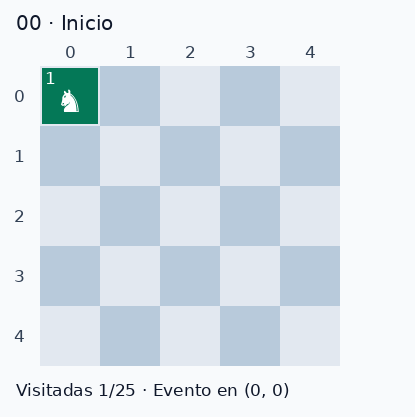

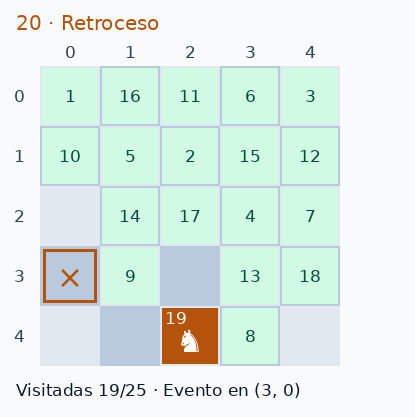

In [11]:
# ===== Reto 4: animacion de MI ejecucion (5x5, inicio (0, 0), orden rotado 5 posiciones) =====
orden_gif = rotar(DESPLAZAMIENTOS, 5)
estado, camino, traza_propia, expansiones = resolver(5, (0, 0), orden=orden_gif)
print(f"Ejecucion propia: {estado}, {expansiones} expansiones, {len(traza_propia)} eventos.")

estados_p = caminos_por_evento(traza_propia)
i_r = next(i for i, e in enumerate(traza_propia) if e[0] == "retroceso")
liberada, vuelve = traza_propia[i_r][1:], estados_p[i_r][-1]
# Destinos que el marco de `vuelve` tenia en su lista, en orden, y cual sigue despues de `liberada`.
lista = ordenar_destinos(5, vuelve, set(estados_p[i_r]), orden_gif, "fijo")
pos = lista.index(liberada)
siguiente = lista[pos + 1] if pos + 1 < len(lista) else None
print(f"Primer retroceso (evento {i_r}): se libera {liberada}; el caballo queda en {vuelve}.")
print(f"Lista de destinos del marco de {vuelve}: {lista}")
print(f"Siguiente alternativa: {siguiente if siguiente else 'ninguna, asi que ese marco tambien retrocede'}.")

prefijo = traza_propia[: i_r + 6]          # empieza en "inicio" y muestra la rama fallida y lo que sigue
display(NotebookImage(data=gif_traza(5, prefijo), format="gif"))
display(NotebookImage(data=ver_fotograma(5, traza_propia, i_r), format="png"))


### Comentario de mi animación (Reto 4)

Animo **mi propia ejecución**, distinta de la del enunciado: 5×5 desde (0, 0), con el orden de desplazamientos **rotado 5 posiciones**. Con ese orden la búsqueda necesita 288 expansiones, frente a las 41 del orden base. El GIF muestra un **prefijo** de la traza que empieza en el evento `inicio` y llega hasta poco después del primer retroceso.

- **Rama fallida:** hasta el evento 19, el caballo avanza sin problemas. En el evento 20 se **libera (3, 0)**: desde ahí no queda ningún salto libre, así que esa llamada devuelve fracaso.
- **Dónde queda el caballo:** en **(4, 2)**, la casilla anterior del camino. El número más alto del tablero desaparece, como predije en el laboratorio.
- **Siguiente alternativa:** la lista de destinos del marco de (4, 2), en el orden rotado, era solo `[(3, 0)]`. Como no le queda otra alternativa, **ese marco también retrocede**. La animación muestra el retroceso en cadena hasta un marco que todavía tiene destinos sin probar, y desde ahí el caballo avanza por otra rama.

El fotograma fijo de abajo es el del primer retroceso: el aspa marca la casilla liberada y el color naranja, la casilla donde quedó el caballo.

In [12]:
# ===== Cambio de parametros: prediccion escrita ANTES de ejecutar, y comprobacion =====
predicciones = [
    ("rotar el orden 2 posiciones -> primer evento despues del inicio",
     ("avance", 2, 1), lambda: resolver(5, (0, 0), orden=rotar(DESPLAZAMIENTOS, 2))[2][1]),
    ("presupuesto=30 en 5x5 -> estado y ultimo evento",
     ("límite", ("límite", 0, 0)), lambda: (lambda r: (r[0], r[2][-1]))(resolver(5, (0, 0), presupuesto=30))),
    ("6x6 cerrado desde (1, 1) con Warnsdorff -> ¿hay circuito?",
     "éxito", lambda: resolver(6, (1, 1), estrategia="warnsdorff", cerrado=True)[0]),
    ("5x5 cerrado -> ¿hay circuito? (argumento de paridad)",
     "fracaso", lambda: resolver(5, (0, 0), cerrado=True, presupuesto=10_000_000)[0]),
]
for texto, predicho, ejecutar in predicciones:
    obtenido = ejecutar()
    print(f"{texto}\n   predicho: {predicho}\n   obtenido: {obtenido}   "
          f"{'OK' if obtenido == predicho else 'DISTINTO'}")
    assert obtenido == predicho


rotar el orden 2 posiciones -> primer evento despues del inicio
   predicho: ('avance', 2, 1)
   obtenido: ('avance', 2, 1)   OK
presupuesto=30 en 5x5 -> estado y ultimo evento
   predicho: ('límite', ('límite', 0, 0))
   obtenido: ('límite', ('límite', 0, 0))   OK
6x6 cerrado desde (1, 1) con Warnsdorff -> ¿hay circuito?
   predicho: éxito
   obtenido: éxito   OK


5x5 cerrado -> ¿hay circuito? (argumento de paridad)
   predicho: fracaso
   obtenido: fracaso   OK


### Cambio de parámetros con predicción previa

El enunciado pide documentar un cambio en otro parámetro y **predecir su efecto antes de ejecutar**. Escribí cada predicción con su razón; la celda anterior las verifica todas con `assert`.

1. **Rotar el orden 2 posiciones.** El orden empieza en `(2, 1), (2, -1), …`. Desde (0, 0), el primer desplazamiento que cae dentro del tablero es `(2, 1)`, así que el primer avance es **(2, 1)** y no (1, 2).
2. **`presupuesto=30` en 5×5.** El orden base necesita 41 expansiones, así que con 30 no alcanza. El resultado es **límite**, y tras desenrollar el camino vuelve al inicio: último evento `("límite", 0, 0)`.
3. **6×6 cerrado desde (1, 1).** 36 es par, así que la paridad no lo prohíbe, y en 6×6 se conocen circuitos cerrados: espero **éxito**.
4. **5×5 cerrado.** 25 es impar, así que por paridad **no existe circuito**. Con presupuesto suficiente, el árbol se agota y el resultado es **fracaso**, no límite.

## Traza manual anotada

Este es un fragmento de la traza de **mi** ejecución del 5×5 desde (0, 0) con el orden base, del evento 18 al 33. El orden de prueba es `(-1,2) (1,2) (2,1) (2,-1) (1,-2) (-1,-2) (-2,-1) (-2,1)`. «Lista del marco» son los destinos libres de esa casilla en el momento en que se calculan, en ese orden.

| Evento | Tipo | Casilla | Largo | Qué pasa |
|---:|---|---|---:|---|
| 18 | avance | (4, 2) | 19 | El marco de (3, 4) tiene la lista `[(4,2), (2,2)]`: toma la primera. |
| 19 | avance | (3, 0) | 20 | El marco de (4, 2) tiene `[(3,0), (2,1)]`: toma (3, 0). |
| 20 | avance | (2, 2) | 21 | El marco de (3, 0) tiene `[(2,2), (1,1)]`: toma (2, 2). |
| 21 | avance | (0, 3) | 22 | El marco de (2, 2) tiene `[(0,3)]`. |
| 22 | avance | (1, 1) | 23 | El marco de (0, 3) tiene `[(1,1)]`. |
| 23 | retroceso | (1, 1) | 22 | (1, 1) tiene la lista **vacía** y faltan 2 casillas: fracaso. El marco de (0, 3) quita (1, 1); no tiene otra opción. |
| 24 | retroceso | (0, 3) | 21 | El marco de (2, 2) quita (0, 3); su lista se acabó. |
| 25 | retroceso | (2, 2) | 20 | El marco de (3, 0) quita (2, 2). El camino vuelve a tener **las mismas 20 casillas en el mismo orden** que antes del evento 20. |
| 26 | avance | (1, 1) | 21 | El mismo marco de (3, 0) pasa a la **siguiente alternativa** de su lista: (1, 1), que en el evento 23 se había liberado. |
| 27 | avance | (0, 3) | 22 | El marco de (1, 1) tiene `[(0,3)]`. |
| 28 | avance | (2, 2) | 23 | El marco de (0, 3) tiene `[(2,2)]`, y desde (2, 2) no queda nada libre. |
| 29–31 | retroceso ×3 | (2,2), (0,3), (1,1) | 20 | Callejón sin salida otra vez; la lista de (3, 0) ya no tiene más destinos. |
| 32 | retroceso | (3, 0) | 19 | El marco de (4, 2) quita (3, 0). |
| 33 | avance | (2, 1) | 20 | El marco de (4, 2) prueba su segunda alternativa: (2, 1). |

**Invariante comprobado a mano:** en los eventos 25 y 32, el camino es idéntico, en contenido y en orden, al que había antes del avance correspondiente (eventos 20 y 19). `visitadas` coincide con `set(camino)` porque cada `pop` va acompañado de su `remove`.

**Pila:**
- antes del evento 23: `… → (4,2) → (3,0) → (2,2) → (0,3) → (1,1)`;
- después del evento 25: `… → (4,2) → (3,0)`; es el marco de (3, 0) el que elige el siguiente destino.

> En el laboratorio rehago a mano un fragmento de la traza como este.

## Lista de entrega

| Pide el enunciado | Dónde está |
|---|---|
| Cuaderno ejecutado | Este cuaderno, ejecutado de arriba abajo en un kernel nuevo |
| Traza manual anotada | Sección «Traza manual anotada» |
| Código propio | Celda de los Retos 1–3 (= `caballo/solver.py`) |
| Tabla comparativa | Celda del Reto 3 y su lectura |
| Fotograma o GIF comentado | Reto 4: GIF de mi ejecución, fotograma del retroceso y comentario |
| Prueba adicional explicada | `reproducir_traza` y su explicación |
| Tres salidas de búsqueda | Celda de pruebas propias: éxito, fracaso y límite |
| Explicación del cierre | «Por qué no hay recorrido cerrado en un tablero impar × impar» |
| Declaración de ayudas | Portada, después del título |